# Problem Statement : House Prices Prediction using TensorFlow Decision Forests

Ask a home buyer to describe their dream house, and they probably won't begin with the height of the basement ceiling or the proximity to an east-west railroad. But this playground competition's dataset proves that much more influences price negotiations than the number of bedrooms or a white-picket fence.

### Step to Follow

1. Requierd Library
2. Load dataset
3. Understand the data

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/data_description.txt
/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv


# 1) Requierd Library

In [2]:
import pandas as pd 
import numpy as np

In [3]:
url = '/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv'
df = pd.read_csv(url)

Understand dataset size

In [4]:
shape_of_the_data = df.shape

print('Shpe of the data :',shape_of_the_data)
print('view the top reocrd',df.head())

Shpe of the data : (1460, 81)
view the top reocrd    Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType

# Find the missing values
let's understand the missing value why becauss the missing value can make big differnt so we to be carful.

Formula is  sum_of_all_value / Numbser_of_values *100 or 

[X1+X2+X+X4+X5...XN/ N *100](http://)

In [5]:
def handling_missing_value(data):
    missing = data.isnull().sum()
    missing_per = (missing / len(data)*100).round(2)
    result = pd.DataFrame({'Missing_Count' : missing , 'missing_%' : missing_per })
    return result[result['Missing_Count']>0].sort_values('missing_%',ascending= False)
handling_missing_value(df)

,Missing_Count,missing_%
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


# 3) Understand the data
Check the data type of each if we know that would be better to make the decession 
so we have 
  * object   43
  * int      35
  * float    3

In [6]:
print(df.dtypes.value_counts())
print(len(df.select_dtypes(include='object').columns.tolist()))

object     43
int64      35
float64     3
Name: count, dtype: int64
43


## list the number columns

we have total of 38 numarical columns 

In [7]:
num_cols = df.select_dtypes(exclude='object').columns.tolist()
print(len(num_cols))
print(num_cols)

38
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']


# Count the unique values in suspicious columns

In [8]:
print(df['MSSubClass'].nunique(), df['MoSold'].nunique())

15 12


# Prove it with the data (don’t just trust my claim)

In [9]:
print((df['PoolArea']== 0 ).sum())
print((df['Fireplaces']== 0 ).sum())
print((df['GarageArea']== 0 ).sum())
print((df['TotalBsmtSF']== 0 ).sum())
print((df['GarageCond']== 0 ).sum())



1453
690
81
37
0


In [10]:
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
             'MasVnrType']
df[none_cols] = df[none_cols].fillna('None')

df['LotFrontage'] = df['LotFrontage'].fillna(df['LotFrontage'].median())
df['MasVnrArea'] = df['MasVnrArea'].fillna(0)
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])
df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['GarageYrBlt'].mean())
handling_missing_value(df)

,Missing_Count,missing_%


**All the value's has been fixed now **

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64
Mean: 180921.19589041095
Median: 163000.0
Skew: 1.8828757597682129


<Axes: >

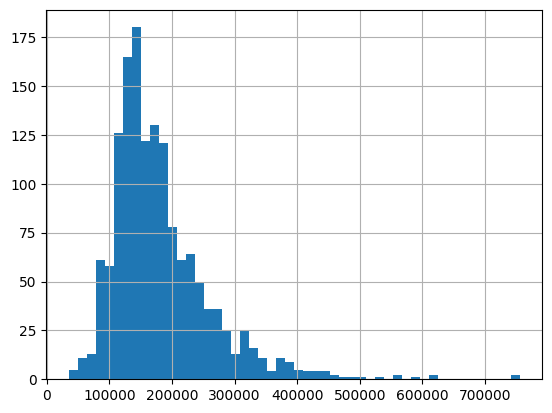

In [11]:
print(df['SalePrice'].describe())
print("Mean:", df['SalePrice'].mean())
print("Median:", df['SalePrice'].median())
print("Skew:", df['SalePrice'].skew())
df['SalePrice'].hist(bins=50)

1. Based on the record we can see that total rows *[1460](http://)*

2. Avg price of the each home *[180921.195890](http://)*

3. what we can understand that from the visual is  most of the house in the range between of *[1.5L](http://)* to *[2L](http://)*.

4. very less we can see the max amount of the price *[7.5L](http://)* also we can see very less min of the home price less then 80k 

In [12]:
print(df[['Neighborhood', 'SalePrice']].groupby('Neighborhood').mean().sort_values('SalePrice', ascending=False))

                  SalePrice
Neighborhood               
NoRidge       335295.317073
NridgHt       316270.623377
StoneBr       310499.000000
Timber        242247.447368
Veenker       238772.727273
Somerst       225379.837209
ClearCr       212565.428571
Crawfor       210624.725490
CollgCr       197965.773333
Blmngtn       194870.882353
Gilbert       192854.506329
NWAmes        189050.068493
SawyerW       186555.796610
Mitchel       156270.122449
NAmes         145847.080000
NPkVill       142694.444444
SWISU         142591.360000
Blueste       137500.000000
Sawyer        136793.135135
OldTown       128225.300885
Edwards       128219.700000
BrkSide       124834.051724
BrDale        104493.750000
IDOTRR        100123.783784
MeadowV        98576.470588


# as we can se the salse by Neighborhood or place 
1. the moset expencive place is '[NoRidge       335295.317073](http://)'
2. most least place is MeadowV        98576.470588

In [13]:
stats = df.groupby('Neighborhood')['SalePrice'].agg(['count', 'mean', 'median']).sort_values('mean')
print(stats)

              count           mean    median
Neighborhood                                
MeadowV          17   98576.470588   88000.0
IDOTRR           37  100123.783784  103000.0
BrDale           16  104493.750000  106000.0
BrkSide          58  124834.051724  124300.0
Edwards         100  128219.700000  121750.0
OldTown         113  128225.300885  119000.0
Sawyer           74  136793.135135  135000.0
Blueste           2  137500.000000  137500.0
SWISU            25  142591.360000  139500.0
NPkVill           9  142694.444444  146000.0
NAmes           225  145847.080000  140000.0
Mitchel          49  156270.122449  153500.0
SawyerW          59  186555.796610  179900.0
NWAmes           73  189050.068493  182900.0
Gilbert          79  192854.506329  181000.0
Blmngtn          17  194870.882353  191000.0
CollgCr         150  197965.773333  197200.0
Crawfor          51  210624.725490  200624.0
ClearCr          28  212565.428571  200250.0
Somerst          86  225379.837209  225500.0
Veenker   